# Network analysis

The delivery analysis found that São Paulo sellers deliver to distant customers far more slowly than local sellers do, and that distance, not seller capacity, is the mechanism. This notebook asks whether that pattern generalises. São Paulo is one large state; the question here is whether **large states in general deliver worse to smaller ones**, treating the platform as a network in which states are nodes and seller-to-customer routes are the connections between them.

It turns out that the obvious version of the question has an unremarkable answer, and a less obvious version has a striking one.

## Scope

Delivered orders purchased between 1 January 2017 and 31 August 2018, as in the delivery analysis: 96,203 orders. Freight and never-delivered orders are drawn from the same period.

In [16]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import statsmodels.formula.api as smf

con = duckdb.connect("../olist.duckdb")

con.sql("""
    CREATE OR REPLACE VIEW model.v_delivery AS
    SELECT o.*, r.seller_state, r.customer_state, r.same_state, r.same_region, r.customer_region
    FROM model.fct_orders o
    LEFT JOIN model.dim_route r USING (route_key)
    WHERE purchase_date BETWEEN DATE '2017-01-01' AND DATE '2018-08-31'
""")

def q(sql):
    return con.sql(sql).df()

def show(sql, n=30):
    con.sql(sql).show(max_rows=n)

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 9,
})
TIER_ORDER = ["Large", "Medium", "Small"]
print("connected")

connected


---

## 1. Classifying states by size

"Big" could mean big on Olist - most orders, most sellers - or big in the world. The first is tempting because it needs no outside data, but it would make the analysis circular: delivery outcomes would be explained with a variable built from the same platform's activity. Population is independent of anything Olist does, so it is used here.

The dataset has no population figures, so they are added from IBGE, Brazil's national statistics office. The figures are IBGE's 2025 estimates as tabulated by geo-ref.net, which is a mild anachronism against 2017–18 orders; the ranking of states by population barely moved between those years, and the tiers depend only on the ranking.

Thresholds are round numbers set before looking at any delivery results: 10 million and above is Large, 3 to 10 million is Medium, below 3 million is Small.

In [17]:
con.sql("""
    CREATE OR REPLACE TABLE model.state_population AS
    SELECT state, population, area_km2,
        CASE WHEN population >= 10000000 THEN 'Large'
             WHEN population >=  3000000 THEN 'Medium'
             ELSE 'Small' END AS size_tier
    FROM (VALUES
        ('AC',   884372,  153150), ('AL',  3220848,   27933), ('AP',   806517,  143454),
        ('AM',  4321616, 1577820), ('BA', 14870907,  567295), ('CE',  9268836,  146348),
        ('DF',  2996899,    5822), ('ES',  4126854,   46184), ('GO',  7423629,  341290),
        ('MA',  7018211,  333366), ('MT',  3893659,  906807), ('MS',  2924631,  358159),
        ('MG', 21393441,  588384), ('PA',  8711196, 1253165), ('PB',  4164468,   56585),
        ('PR', 11890517,  199709), ('PE',  9562007,   98938), ('PI',  3384547,  252378),
        ('RJ', 17223547,   43910), ('RN',  3455236,   53307), ('RS', 11233263,  282062),
        ('RO',  1751950,  238513), ('RR',   738772,  225116), ('SC',  8187029,   95443),
        ('SP', 46081801,  248809), ('SE',  2299425,   22050), ('TO',  1586859,  278421)
    ) AS t(state, population, area_km2)
""")

show("""
    SELECT size_tier, COUNT(*) AS states,
           string_agg(state, ', ' ORDER BY population DESC) AS members
    FROM model.state_population
    GROUP BY 1 ORDER BY MIN(CASE size_tier WHEN 'Large' THEN 1 WHEN 'Medium' THEN 2 ELSE 3 END)
""")

┌───────────┬────────┬────────────────────────────────────────────────────┐
│ size_tier │ states │                      members                       │
│  varchar  │ int64  │                      varchar                       │
├───────────┼────────┼────────────────────────────────────────────────────┤
│ Large     │      6 │ SP, MG, RJ, BA, PR, RS                             │
│ Medium    │     13 │ PE, CE, PA, SC, GO, MA, AM, PB, ES, MT, RN, PI, AL │
│ Small     │      8 │ DF, MS, SE, RO, TO, AC, AP, RR                     │
└───────────┴────────┴────────────────────────────────────────────────────┘



Six Large states, thirteen Medium and eight Small.

One assignment needs flagging now rather than later. The Federal District, Brasília, falls into Small by about 3,000 people - 2,996,899 against a 3,000,000 line. It is the national capital, it is geographically tiny and dense, and it had the fastest local deliveries in the delivery analysis. It sits in Small because the rule was fixed before the results were seen; section 9 tests whether the conclusions depend on it.

In [18]:
con.sql("""
    CREATE OR REPLACE VIEW model.v_delivery_tiered AS
    SELECT
        v.*,
        ps.size_tier AS seller_tier,
        pc.size_tier AS customer_tier,
        CASE WHEN v.distance_km <  200 THEN '1: under 200 km'
             WHEN v.distance_km <  500 THEN '2: 200-500 km'
             WHEN v.distance_km < 1000 THEN '3: 500-1000 km'
             WHEN v.distance_km < 2000 THEN '4: 1000-2000 km'
             WHEN v.distance_km IS NOT NULL THEN '5: 2000 km and over' END AS distance_band
    FROM model.v_delivery v
    JOIN model.state_population ps ON ps.state = v.seller_state
    JOIN model.state_population pc ON pc.state = v.customer_state
""")
print(f"orders with both tiers: {con.execute('SELECT COUNT(*) FROM model.v_delivery_tiered').fetchall()[0][0]:,}")

orders with both tiers: 96,203


---

## 2. The route network

Every order travels from a seller's state to a customer's state. Grouping both ends by tier gives a three-by-three network of routes.

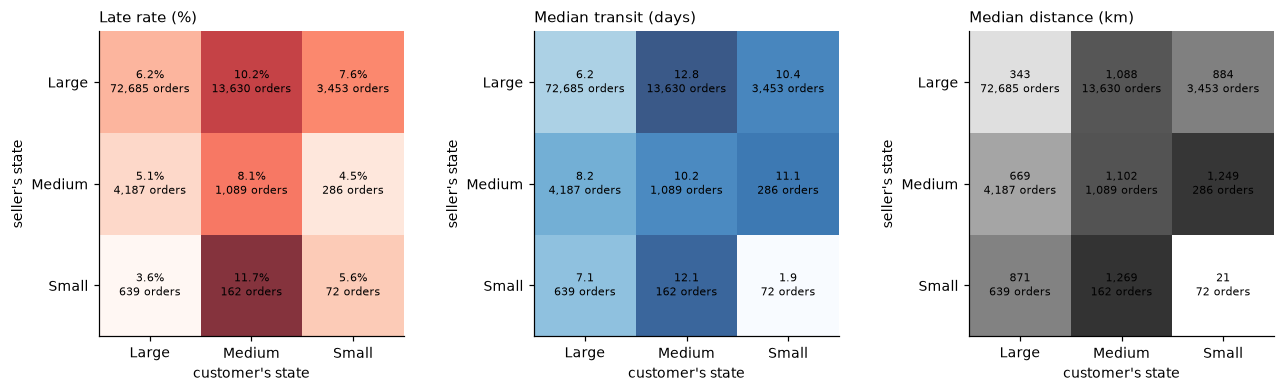

,seller_tier,customer_tier,orders,late_pct,median_transit,median_km
0,Large,Large,72685,6.21,6.15,342.98
1,Large,Medium,13630,10.21,12.76,1087.67
2,Large,Small,3453,7.65,10.39,884.35
3,Medium,Large,4187,5.09,8.19,669.40
4,Medium,Medium,1089,8.08,10.21,1101.88
5,Medium,Small,286,4.55,11.14,1248.63
6,Small,Large,639,3.60,7.08,870.75
7,Small,Medium,162,11.73,12.07,1268.87
8,Small,Small,72,5.56,1.91,20.52


In [19]:
od = q("""
    SELECT
        seller_tier, customer_tier,
        COUNT(*)                            AS orders,
        100 * AVG(is_late::INT)             AS late_pct,
        MEDIAN(transit_days)                AS median_transit,
        MEDIAN(distance_km)                 AS median_km
    FROM model.v_delivery_tiered
    GROUP BY 1, 2
""")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, col, title, fmt, cmap in [
        (axes[0], "late_pct",       "Late rate (%)",          "{:.1f}%", "Reds"),
        (axes[1], "median_transit", "Median transit (days)",  "{:.1f}",  "Blues"),
        (axes[2], "median_km",      "Median distance (km)",   "{:,.0f}", "Greys")]:
    grid = od.pivot(index="seller_tier", columns="customer_tier", values=col).loc[TIER_ORDER, TIER_ORDER]
    n    = od.pivot(index="seller_tier", columns="customer_tier", values="orders").loc[TIER_ORDER, TIER_ORDER]
    ax.imshow(grid.to_numpy(), cmap=cmap, alpha=0.8)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, fmt.format(grid.iat[i, j]) + f"\n{int(n.iat[i, j]):,} orders",
                    ha="center", va="center", fontsize=7.5)
    ax.set_xticks(range(3), TIER_ORDER); ax.set_yticks(range(3), TIER_ORDER)
    ax.set_xlabel("customer's state"); ax.set_ylabel("seller's state")
    ax.set_title(title, loc="left", fontsize=10); ax.grid(False)
plt.tight_layout()
plt.show()

od.sort_values(["seller_tier", "customer_tier"]).reset_index(drop=True).round(2)

Three quarters of all orders travel Large → Large, and those are the best-performing routes: 6.2% late, about six days in transit.

Large → Medium is clearly worse at 10.2% late and nearly thirteen days in transit, which is the pattern the question anticipated. Large states do appear to deliver worse to smaller ones.

But the third panel is the problem. Large → Large routes have a median length of 343 km. Large → Medium routes have a median of 1,088 km. Every cell that looks bad is also a long-distance cell, and the delivery analysis already showed that distance alone triples the late rate. Before attributing anything to state size, distance has to be held constant.

---

## 3. Holding distance constant

The comparison that matters is between customers in different tiers who are the **same distance** from their seller.

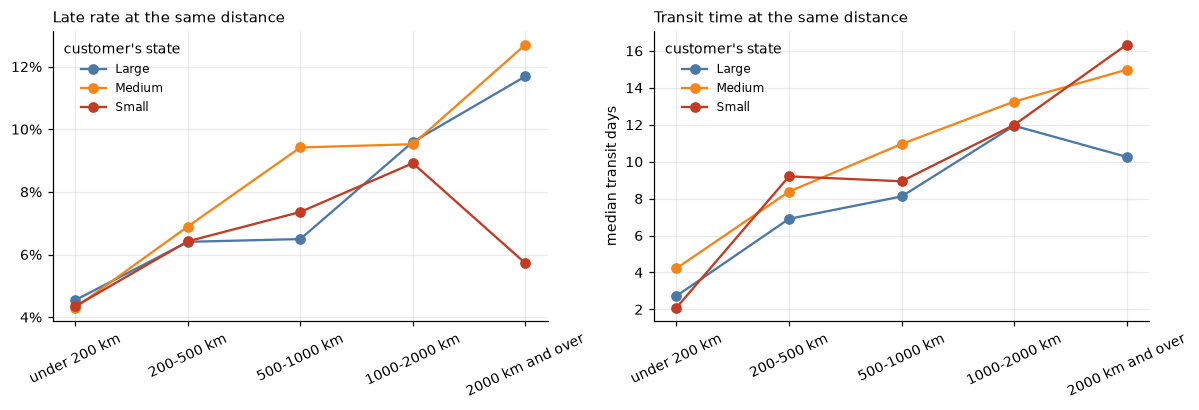

late_pct                orders                
customer_tier          Large Medium Small    Large  Medium   Small
distance_band                                                     
1: under 200 km         4.54   4.30  4.35  24129.0   395.0    69.0
2: 200-500 km           6.41   6.89  6.42  28333.0  1697.0   109.0
3: 500-1000 km          6.49   9.42  7.36  18615.0  5000.0  2079.0
4: 1000-2000 km         9.60   9.52  8.92   5721.0  3045.0   942.0
5: 2000 km and over    11.69  12.70  5.72    479.0  4676.0   437.0

In [20]:
band = q("""
    SELECT distance_band, customer_tier,
           COUNT(*)                         AS orders,
           100 * AVG(is_late::INT)          AS late_pct,
           MEDIAN(transit_days)             AS median_transit
    FROM model.v_delivery_tiered
    WHERE distance_band IS NOT NULL
    GROUP BY 1, 2
""")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
colors = {"Large": "#4C78A8", "Medium": "#F58518", "Small": "#C23B22"}
for t in TIER_ORDER:
    s = band[band.customer_tier == t].sort_values("distance_band")
    a1.plot(s["distance_band"].str[3:], s["late_pct"], marker="o", color=colors[t], label=t)
    a2.plot(s["distance_band"].str[3:], s["median_transit"], marker="o", color=colors[t], label=t)
a1.set_title("Late rate at the same distance", loc="left", fontsize=10)
a1.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
a2.set_title("Transit time at the same distance", loc="left", fontsize=10)
a2.set_ylabel("median transit days")
for a in (a1, a2):
    a.tick_params(axis="x", rotation=25); a.legend(title="customer's state", frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

band.pivot(index="distance_band", columns="customer_tier", values=["late_pct", "orders"]).round(2)

The left chart answers the original question. At the same distance, the three lines mostly sit on top of each other. The one clear exception is Medium states at 500–1,000 km, about three points worse than Large states at that distance. Elsewhere the differences are within a point or two, and the Small-state line at 2,000 km and over is based on only 437 orders.

A single number per tier makes this precise. Each tier's late rate is recalculated as if its customers had the same mix of distances as the platform as a whole - a technique called direct standardisation.

In [21]:
def standardised(tier_col="customer_tier", table="model.v_delivery_tiered"):
    return q(f"""
        WITH w AS (
            SELECT distance_band, COUNT(*) * 1.0 / SUM(COUNT(*)) OVER () AS weight
            FROM {table} WHERE distance_band IS NOT NULL GROUP BY 1),
        tb AS (
            SELECT {tier_col} AS tier, distance_band,
                   AVG(is_late::INT) AS late, MEDIAN(transit_days) AS transit
            FROM {table} WHERE distance_band IS NOT NULL GROUP BY 1, 2),
        raw AS (
            SELECT {tier_col} AS tier, 100 * AVG(is_late::INT) AS raw_late_pct,
                   AVG(transit_days) AS raw_avg_transit
            FROM {table} WHERE distance_band IS NOT NULL GROUP BY 1)
        SELECT tb.tier,
               ANY_VALUE(raw.raw_late_pct)            AS raw_late_pct,
               100 * SUM(tb.late * w.weight)          AS distance_adjusted_late_pct,
               ANY_VALUE(raw.raw_avg_transit)         AS raw_avg_transit,
               SUM(tb.transit * w.weight)             AS distance_adjusted_transit
        FROM tb JOIN w USING (distance_band) JOIN raw USING (tier)
        GROUP BY 1 ORDER BY CASE tb.tier WHEN 'Large' THEN 1 WHEN 'Medium' THEN 2 ELSE 3 END
    """).round(2)

standardised()

,tier,raw_late_pct,distance_adjusted_late_pct,raw_avg_transit,distance_adjusted_transit
0,Large,6.11,6.58,8.16,6.87
1,Medium,10.05,7.51,14.64,8.89
2,Small,7.48,6.35,12.44,8.01


Before adjustment, Medium-state customers are late 10.1% of the time against 6.1% for Large states, a gap of four points. After adjustment the gap is under one point, 7.5% against 6.6%. **Distance explains about three quarters of the late-rate gap**, and Small states end up level with Large ones.

So the obvious version of the question has an unremarkable answer: large states do not deliver late to smaller states much more often than distance alone would predict.

The right-hand chart and the last column of the table tell a different story.

---

## 4. The inequality the late rate cannot see

At the same distance, customers in smaller states **wait longer**. The adjusted transit time is 6.9 days for Large-state customers, 8.9 for Medium and 8.0 for Small. In the longest band the gap is widest: 10.3 days for Large-state customers against 15.0 for Medium and 16.3 for Small.

Customers in smaller states wait days longer for the same journey, yet the late rate barely registers it. The reason is the promise.

In [22]:
show("""
    SELECT distance_band, customer_tier,
           COUNT(*)                                                  AS orders,
           ROUND(MEDIAN(transit_days), 1)                            AS median_transit,
           ROUND(AVG(promised_days), 1)                              AS promised_days,
           ROUND(AVG(promised_days) - AVG(delivery_days), 1)         AS slack_days,
           ROUND(100 * AVG(is_late::INT), 2)                         AS late_pct
    FROM model.v_delivery_tiered
    WHERE distance_band IS NOT NULL
    GROUP BY 1, 2
    ORDER BY 1, CASE customer_tier WHEN 'Large' THEN 1 WHEN 'Medium' THEN 2 ELSE 3 END
""")

┌─────────────────────┬───────────────┬────────┬────────────────┬───────────────┬────────────┬──────────┐
│    distance_band    │ customer_tier │ orders │ median_transit │ promised_days │ slack_days │ late_pct │
│       varchar       │    varchar    │ int64  │     double     │    double     │   double   │  double  │
├─────────────────────┼───────────────┼────────┼────────────────┼───────────────┼────────────┼──────────┤
│ 1: under 200 km     │ Large         │  24129 │            2.7 │          16.9 │        9.8 │     4.54 │
│ 1: under 200 km     │ Medium        │    395 │            4.2 │          19.8 │       11.8 │      4.3 │
│ 1: under 200 km     │ Small         │     69 │            2.1 │          16.4 │        9.5 │     4.35 │
│ 2: 200-500 km       │ Large         │  28333 │            6.9 │          24.1 │       12.1 │     6.41 │
│ 2: 200-500 km       │ Medium        │   1697 │            8.4 │          26.0 │       12.0 │     6.89 │
│ 2: 200-500 km       │ Small         │    109

The slack column - promised days minus actual days - is close to twelve in almost every cell, from 9.5 to 13.2. Olist does not promise a fixed delivery time and then succeed or fail against it. It estimates each journey and adds roughly twelve days. Where transit is slower, the promise is longer, and the late rate stays roughly level.

The one cell that breaks the pattern shows it most clearly. Small-state customers more than 2,000 km from their seller are given **18.2 days of slack** and a promise of **40.6 days**. They have the slowest transit of any group, 16.3 days, and the lowest late rate in their distance band, 5.7%.

Judged by the late rate, a customer in Roraima receives the same service as a customer in São Paulo. Judged by how long they wait, they do not.

---

## 5. What customers actually judge

That raises a question the late rate cannot answer: does the longer wait matter to the customer, if the promise is kept?

In [23]:
show("""
    SELECT customer_tier,
           COUNT(*)                             AS reviewed_on_time_orders,
           ROUND(AVG(delivery_days), 1)         AS avg_days_waited,
           ROUND(AVG(review_score), 2)          AS avg_review
    FROM model.v_delivery_tiered
    WHERE has_review AND NOT is_late
    GROUP BY 1 ORDER BY CASE customer_tier WHEN 'Large' THEN 1 WHEN 'Medium' THEN 2 ELSE 3 END
""")

┌───────────────┬─────────────────────────┬─────────────────┬────────────┐
│ customer_tier │ reviewed_on_time_orders │ avg_days_waited │ avg_review │
│    varchar    │          int64          │     double      │   double   │
├───────────────┼─────────────────────────┼─────────────────┼────────────┤
│ Large         │                   72366 │            10.0 │        4.3 │
│ Medium        │                   13301 │            15.6 │       4.26 │
│ Small         │                    3515 │            13.9 │       4.28 │
└───────────────┴─────────────────────────┴─────────────────┴────────────┘



Among orders that arrived on time, Medium-state customers waited 15.6 days on average against 10.0 for Large-state customers - more than half as long again - and rated their orders almost identically, 4.26 against 4.30.

Customers do not judge the absolute length of the wait. A long wait that is normal for where they live, and that matches what they were told, costs almost nothing in reviews; a broken promise costs a great deal, as the delivery analysis showed. This is the strongest argument in the project for treating the promise as a product decision: a longer promise that is kept is worth more than a shorter one that is missed.

The promise analysis adds a qualification. An order that is unusually slow *for its own route* is rated lower even when it arrives on time, so customers also compare against what is normal, not only against the promised date.

What the data cannot show is the cost of a long promise *before* purchase - customers who saw forty days and did not buy never appear in an orders table.

---

## 6. Are small-state customers more forgiving?

If customers in remote states are used to slow delivery, they might also be more tolerant when it is late. The comparison has to hold lateness constant, and it has to check that review timing is similar across tiers, since reviews written before the parcel arrives are much harsher.

In [24]:
rv = q("""
    SELECT customer_tier,
           CASE WHEN days_vs_promise <= 0 THEN 'on_time'
                WHEN days_vs_promise <= 5 THEN 'late_1_5'
                ELSE 'late_6_plus' END                  AS lateness,
           COUNT(*)                                     AS n,
           AVG(review_score)                            AS score,
           VAR_SAMP(review_score)                       AS var,
           100 * AVG(review_before_delivery::INT)       AS pct_before_arrival
    FROM model.v_delivery_tiered
    WHERE has_review
    GROUP BY 1, 2
""")

rows = []
for t in TIER_ORDER:
    on = rv[(rv.customer_tier == t) & (rv.lateness == "on_time")].iloc[0]
    for lb in ["late_1_5", "late_6_plus"]:
        la = rv[(rv.customer_tier == t) & (rv.lateness == lb)].iloc[0]
        pen = on.score - la.score
        se = np.sqrt(on["var"] / on.n + la["var"] / la.n)
        rows.append((t, lb, int(la.n), round(la.pct_before_arrival, 1),
                     round(pen, 2), round(pen - 1.96 * se, 2), round(pen + 1.96 * se, 2)))

pd.DataFrame(rows, columns=["customer_tier", "lateness", "late_reviews", "pct_written_before_arrival",
                            "stars_lost_vs_on_time", "ci_low", "ci_high"])

,customer_tier,lateness,late_reviews,pct_written_before_arrival,stars_lost_vs_on_time,ci_low,ci_high
0,Large,late_1_5,2029,62.0,1.29,1.22,1.36
1,Large,late_6_plus,2614,99.8,2.56,2.51,2.61
2,Medium,late_1_5,564,59.8,1.28,1.15,1.42
3,Medium,late_6_plus,891,99.8,2.52,2.44,2.61
4,Small,late_1_5,128,66.4,1.54,1.26,1.83
5,Small,late_6_plus,152,100.0,2.61,2.42,2.81


They are not. One to five days late costs 1.29 stars in Large states, 1.28 in Medium states and 1.54 in Small states - if anything slightly harsher, though the intervals overlap. Six or more days late costs about two and a half stars everywhere. The share of reviews written before arrival is similar across tiers, so timing does not explain the result either.

Together with section 5, this gives a consistent picture. Customers in smaller states are not resigned to poor service. They accept a long wait when they are told about it, and they react to a broken promise exactly as strongly as anyone else.

---

## 7. Do smaller states pay more?

Slower transit is one cost of living far from the sellers. Freight is the other. Freight is driven mainly by how far a parcel goes and how much room it takes, so the comparison has to control for both.

The model uses single-item, single-seller orders, so that each freight charge belongs to one parcel. Freight, distance and cubed weight are taken in logarithms, because freight grows proportionally rather than by fixed amounts, and the tier coefficients then read as percentage premiums over Large states.

In [25]:
fr = q("""
    SELECT freight_total, distance_km, customer_tier,
           GREATEST(COALESCE(weight_g, 0), COALESCE(volume_cm3 / 6.0, 0)) / 1000.0 AS billable_kg
    FROM model.v_delivery_tiered
    WHERE distance_km IS NOT NULL AND freight_total > 0 AND n_sellers = 1 AND n_items = 1
""")
fr["log_freight"]  = np.log(fr["freight_total"])
fr["log_distance"] = np.log1p(fr["distance_km"])
fr["log_kg"]       = np.log(fr["billable_kg"].clip(lower=0.05))

base = smf.ols("log_freight ~ log_distance + log_kg", fr).fit()
full = smf.ols("log_freight ~ log_distance + log_kg + C(customer_tier, Treatment('Large'))", fr).fit(cov_type="HC1")

print(f"orders: {len(fr):,}")
print(f"R-squared, distance and weight only: {base.rsquared:.3f}")
print(f"R-squared, adding customer tier:    {full.rsquared:.3f}")

ci = full.conf_int()
pd.DataFrame({
    "coefficient": full.params,
    "ci_low": ci[0], "ci_high": ci[1],
    "as_percentage": 100 * (np.exp(full.params) - 1),
}).round(3)

orders: 85,866
R-squared, distance and weight only: 0.568
R-squared, adding customer tier:    0.581


,coefficient,ci_low,ci_high,as_percentage
Intercept,1.670,1.660,1.680,431.418
"C(customer_tier, Treatment('Large'))[T.Medium]",0.165,0.158,0.172,17.922
"C(customer_tier, Treatment('Large'))[T.Small]",0.113,0.100,0.127,11.981
log_distance,0.190,0.188,0.192,20.911
log_kg,0.193,0.190,0.196,21.290


Distance and cubed weight together explain 57% of the variation in freight across 85,866 single-item orders. Holding both fixed, customers in Medium states pay **17.9% more** for freight and customers in Small states **12.0% more** than customers in Large states, with narrow confidence intervals.

The other coefficients are worth noting too. Doubling the distance raises freight by only about 14%, and doubling the billable weight by about the same, so a large part of every freight charge is a fixed base rather than a per-kilometre or per-kilo cost.

This needs careful reading before it is called unfair. Distance here is a straight line. Reaching the Amazon states often involves river legs and poor roads, so a straight-line kilometre there is a longer and harder real journey, and part of the premium is likely to be genuine logistics cost. What the customer experiences is the same either way: in smaller states they pay more for freight and wait longer for delivery at the same distance.

---

## 8. Orders that never arrive

The delivery analysis found 1,174 orders that reached a carrier and never registered a delivery. Their spread across the network is part of the same picture.

In [26]:
lost = q("""
    WITH o AS (
        SELECT o.order_id, (NOT o.is_delivered) AS never_delivered,
               cu.state AS customer_state, cu.lat AS clat, cu.lng AS clng,
               s.lat AS slat, s.lng AS slng
        FROM clean.orders o
        JOIN clean.customers cu USING (customer_id)
        JOIN model.order_items_rollup r USING (order_id)
        LEFT JOIN clean.sellers s ON s.seller_id = r.main_seller_id
        WHERE CAST(o.purchase_ts AS DATE) BETWEEN DATE '2017-01-01' AND DATE '2018-08-31'
          AND o.carrier_ts IS NOT NULL),
    d AS (
        SELECT *, 2 * 6371 * ASIN(SQRT(
                    POWER(SIN(RADIANS(clat - slat) / 2), 2) +
                    COS(RADIANS(slat)) * COS(RADIANS(clat)) *
                    POWER(SIN(RADIANS(clng - slng) / 2), 2))) AS km
        FROM o)
    SELECT
        CASE WHEN km <  200 THEN '1: under 200 km'  WHEN km <  500 THEN '2: 200-500 km'
             WHEN km < 1000 THEN '3: 500-1000 km'   WHEN km < 2000 THEN '4: 1000-2000 km'
             ELSE '5: 2000 km and over' END              AS distance_band,
        COUNT(*)                                         AS handed_to_carrier,
        SUM(never_delivered::INT)                        AS never_delivered,
        ROUND(100.0 * AVG(never_delivered::INT), 2)      AS pct_never_delivered
    FROM d WHERE km IS NOT NULL
    GROUP BY 1 ORDER BY 1
""")
lost

,distance_band,handed_to_carrier,never_delivered,pct_never_delivered
0,1: under 200 km,24818,225.0,0.91
1,2: 200-500 km,30512,373.0,1.22
2,3: 500-1000 km,25985,292.0,1.12
3,4: 1000-2000 km,9859,151.0,1.53
4,5: 2000 km and over,5718,126.0,2.20


In [27]:
show("""
    SELECT p.size_tier AS customer_tier,
           COUNT(*)                                        AS handed_to_carrier,
           SUM((NOT o.is_delivered)::INT)                  AS never_delivered,
           ROUND(100.0 * AVG((NOT o.is_delivered)::INT), 2) AS pct_never_delivered
    FROM clean.orders o
    JOIN clean.customers cu USING (customer_id)
    JOIN model.state_population p ON p.state = cu.state
    WHERE CAST(o.purchase_ts AS DATE) BETWEEN DATE '2017-01-01' AND DATE '2018-08-31'
      AND o.carrier_ts IS NOT NULL
    GROUP BY 1 ORDER BY CASE p.size_tier WHEN 'Large' THEN 1 WHEN 'Medium' THEN 2 ELSE 3 END
""")

┌───────────────┬───────────────────┬─────────────────┬─────────────────────┐
│ customer_tier │ handed_to_carrier │ never_delivered │ pct_never_delivered │
│    varchar    │       int64       │     int128      │       double        │
├───────────────┼───────────────────┼─────────────────┼─────────────────────┤
│ Large         │             78391 │             881 │                1.12 │
│ Medium        │             15124 │             243 │                1.61 │
│ Small         │              3861 │              50 │                 1.3 │
└───────────────┴───────────────────┴─────────────────┴─────────────────────┘



The share of parcels that never arrive more than doubles with distance, from 0.91% under 200 km to 2.20% beyond 2,000 km, and it is higher for Medium-state customers (1.61%) than for Large-state customers (1.12%).

On the longest routes, the full picture of failure is therefore about 12% of delivered orders arriving late plus a further 2% that never arrive at all - and none of the second group appears in the late rate.

---

## 9. Does Brasília change the conclusions?

Brasília was placed in the Small tier by a margin of about 3,000 people. Because it is a dense capital with excellent logistics, it could be making the Small tier look better than the rest of its members. Moving it to Medium and repeating the key results tests that.

In [28]:
con.sql("""
    CREATE OR REPLACE TEMP VIEW v_tiered_df_medium AS
    SELECT * REPLACE (
        CASE WHEN customer_state = 'DF' THEN 'Medium' ELSE customer_tier END AS customer_tier)
    FROM model.v_delivery_tiered
""")

print("Distance-standardised results with Brasília moved to Medium:")
standardised(table="v_tiered_df_medium")

Distance-standardised results with Brasília moved to Medium:


,tier,raw_late_pct,distance_adjusted_late_pct,raw_avg_transit,distance_adjusted_transit
0,Large,6.11,6.58,8.16,6.87
1,Medium,9.56,7.26,14.09,8.59
2,Small,9.38,6.50,15.36,12.53


In [29]:
fr2 = q("""
    SELECT freight_total, distance_km, customer_tier,
           GREATEST(COALESCE(weight_g, 0), COALESCE(volume_cm3 / 6.0, 0)) / 1000.0 AS billable_kg
    FROM v_tiered_df_medium
    WHERE distance_km IS NOT NULL AND freight_total > 0 AND n_sellers = 1 AND n_items = 1
""")
fr2["log_freight"]  = np.log(fr2["freight_total"])
fr2["log_distance"] = np.log1p(fr2["distance_km"])
fr2["log_kg"]       = np.log(fr2["billable_kg"].clip(lower=0.05))
full2 = smf.ols("log_freight ~ log_distance + log_kg + C(customer_tier, Treatment('Large'))", fr2).fit(cov_type="HC1")

pd.Series(100 * (np.exp(full2.params) - 1), name="freight premium %").filter(like="tier").round(1)

C(customer_tier, Treatment('Large'))[T.Medium]    15.7
C(customer_tier, Treatment('Large'))[T.Small]     27.8
Name: freight premium %, dtype: float64

The conclusions hold, and two of them get stronger.

- **The late rate** stays level after distance adjustment: 7.3% for Medium and 6.5% for Small against 6.6% for Large.
- **The waiting-time gap** widens sharply for the remaining Small states: 12.5 days of adjusted transit against 6.9 for Large-state customers. Brasília had been pulling the Small-tier average down.
- **The freight premium** for Small states rises from 12% to 28%.

Brasília was masking part of the disadvantage of the smallest states, not creating it.

---

## 10. What this analysis establishes

**Large states do not deliver late to smaller states much more often than distance predicts.** Raw late rates make it look that way - 10.2% on Large → Medium routes against 6.2% on Large → Large - but those routes are three times longer. Adjusted to the same mix of distances, about three quarters of the gap disappears, and the late rate is roughly level across state sizes.

**Customers in smaller states wait longer for the same journey.** At equal distance, adjusted transit is 6.9 days for Large-state customers, 8.9 for Medium and 8.0 for Small, rising to 12.5 for Small states once Brasília is excluded. In the longest distance band, customers in smaller states wait five to six days longer.

**The late rate hides this because the promise absorbs it.** Olist adds about twelve days of slack to almost every route, and gives the remotest customers eighteen days of slack and a forty-day promise. Measured by the company's own metric, service is equal across the country; measured by waiting time, it is not.

**Customers do not judge the absolute length of the wait.** On-time orders in Medium states took more than half as long again as in Large states and were rated almost identically, 4.26 against 4.30. Customers in smaller states are not more forgiving of lateness either: a broken promise costs the same number of stars everywhere.

**Smaller states also pay more.** At the same straight-line distance and cubed weight, freight is 18% higher for Medium-state customers and 12–28% higher for Small-state customers, depending on whether Brasília is counted. Part of this is probably real logistics cost on harder routes.

**Failures that never reach the late rate are concentrated in the same places.** Parcels that never arrive rise from 0.9% on short routes to 2.2% beyond 2,000 km.

Two consequences carry forward. Expected delivery time differs so much by route that any useful definition of "slower than normal" has to be route-specific, which the promise analysis builds. And because customers react to the promise rather than the wait, how the promise is set matters as much as how fast parcels move.

In [30]:
con.close()
print("connection closed")

connection closed
